# Gantt Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Horizontal bars placed on a time axis, one per task, showing start, duration and end. It is the standard view of a schedule: sequence, overlap and progress.

## When to use

- Plan or communicate project schedules, phases and milestones
- Show overlapping activities and their timing
- Track progress against plan

## Avoid when

- Complex dependency networks are the main concern (use a network/PERT diagram)
- There are hundreds of tasks (group into phases)

## Alternatives

- Event timeline
- Swimmer plot (clinical)

## Design tips

- Color by phase or owner, not by task
- Mark 'today' with a vertical line
- Shade completed portions to show progress

## Example

A 6-month software project with tasks in three phases.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
tasks = pd.DataFrame([
    ("Requirements", "Plan", "2025-01-06", 14, 1.0),
    ("Architecture", "Plan", "2025-01-20", 14, 1.0),
    ("Backend API", "Build", "2025-02-03", 42, 0.8),
    ("Frontend UI", "Build", "2025-02-17", 49, 0.6),
    ("Data migration", "Build", "2025-03-10", 21, 0.3),
    ("Integration test", "Test", "2025-03-31", 21, 0.0),
    ("User acceptance", "Test", "2025-04-21", 14, 0.0),
    ("Launch", "Test", "2025-05-05", 5, 0.0),
], columns=["task", "phase", "start", "days", "done"])
tasks["start"] = pd.to_datetime(tasks["start"])
tasks["end"] = tasks["start"] + pd.to_timedelta(tasks["days"], unit="D")
tasks

,task,phase,start,days,done,end
0,Requirements,Plan,2025-01-06,14,1.0,2025-01-20
1,Architecture,Plan,2025-01-20,14,1.0,2025-02-03
2,Backend API,Build,2025-02-03,42,0.8,2025-03-17
3,Frontend UI,Build,2025-02-17,49,0.6,2025-04-07
4,Data migration,Build,2025-03-10,21,0.3,2025-03-31
5,Integration test,Test,2025-03-31,21,0.0,2025-04-21
6,User acceptance,Test,2025-04-21,14,0.0,2025-05-05
7,Launch,Test,2025-05-05,5,0.0,2025-05-10


### Plot

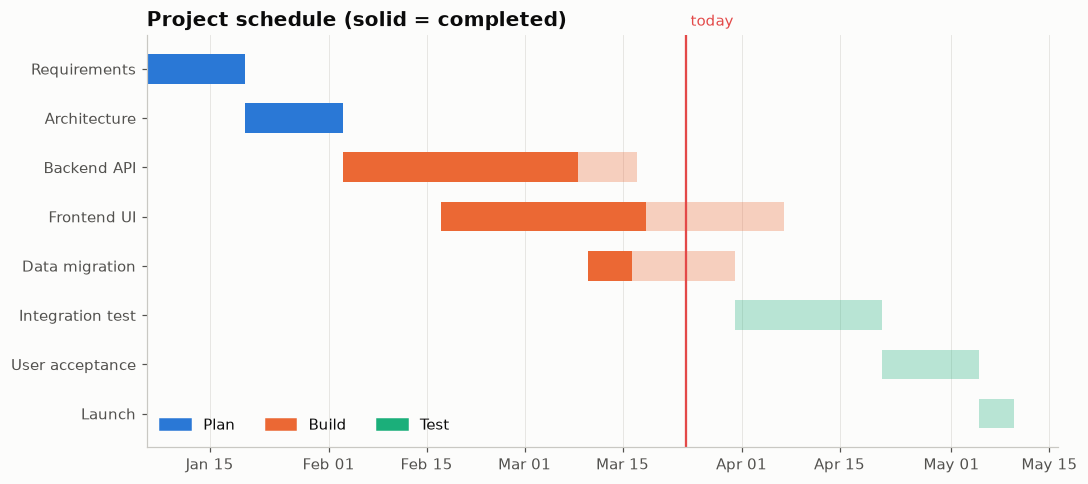

In [3]:
import matplotlib.dates as mdates
phase_color = {"Plan": PALETTE[0], "Build": PALETTE[1], "Test": PALETTE[2]}
today = pd.Timestamp("2025-03-24")
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, r in tasks.iterrows():
    c = phase_color[r["phase"]]
    ax.barh(i, r["days"], left=r["start"], color=c, alpha=0.3, height=0.6)
    ax.barh(i, r["days"] * r["done"], left=r["start"], color=c, height=0.6)
ax.axvline(today, color="#e34948", linewidth=1.5)
ax.text(today, -0.8, " today", color="#e34948", va="bottom")
ax.set_yticks(range(len(tasks)), tasks["task"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in phase_color.values()]
ax.legend(handles, phase_color.keys(), loc="lower left", ncol=3)
ax.set_title("Project schedule (solid = completed)")
fig.tight_layout()
plt.show()

---
Standalone script: [`gantt_chart.py`](gantt_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)